<a href="https://colab.research.google.com/github/ny6in/AIML/blob/main/Aiml1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.model_selection import train_test_split

In [ ]:
from google.colab import files

uploaded = files.upload()


Saving archive.zip to archive (1).zip


In [ ]:
print(uploaded.keys())


dict_keys(['archive (1).zip'])


If the uploaded file is not named `archive.zip`, you can rename it to `archive.zip` by replacing `your_uploaded_file.zip` with the actual name of your uploaded file. This will ensure that the subsequent cells can find and extract the archive.


In [ ]:
# Replace 'your_uploaded_file.zip' with the actual name of the file you uploaded
# import os
# if 'your_uploaded_file.zip' in uploaded:
#     os.rename('your_uploaded_file.zip', 'archive.zip')
#     print('File renamed to archive.zip')
# else:
#     print('Error: The specified file was not found among the uploaded files.')


In [ ]:
import zipfile

with zipfile.ZipFile("archive.zip","r") as zip_ref:
    zip_ref.extractall("dataset")

print("Dataset Extracted Successfully")

Dataset Extracted Successfully


In [ ]:
import os

os.listdir("dataset")

['6 class csv.csv']

In [ ]:
df = pd.read_csv("dataset/6 class csv.csv")

df.head()

,Temperature (K),Luminosity(L/Lo),Radius(R/Ro),Absolute magnitude(Mv),Star type,Star color,Spectral Class
0,3068,0.002400,0.1700,16.12,0,Red,M
1,3042,0.000500,0.1542,16.60,0,Red,M
2,2600,0.000300,0.1020,18.70,0,Red,M
3,2800,0.000200,0.1600,16.65,0,Red,M
4,1939,0.000138,0.1030,20.06,0,Red,M


In [ ]:
print(df.head())

print(df.info())

print(df.describe())

   Temperature (K)  Luminosity(L/Lo)  Radius(R/Ro)  Absolute magnitude(Mv)  \
0             3068          0.002400        0.1700                   16.12   
1             3042          0.000500        0.1542                   16.60   
2             2600          0.000300        0.1020                   18.70   
3             2800          0.000200        0.1600                   16.65   
4             1939          0.000138        0.1030                   20.06   

   Star type Star color Spectral Class  
0          0        Red              M  
1          0        Red              M  
2          0        Red              M  
3          0        Red              M  
4          0        Red              M  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 240 entries, 0 to 239
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Temperature (K)         240 non-null    int64  
 1   Luminosity(L/Lo) 

In [ ]:
print("Rows :",df.shape[0])

print("Columns :",df.shape[1])

print(df.dtypes)

print(df.isnull().sum())

Rows : 240
Columns : 7
Temperature (K)             int64
Luminosity(L/Lo)          float64
Radius(R/Ro)              float64
Absolute magnitude(Mv)    float64
Star type                   int64
Star color                 object
Spectral Class             object
dtype: object
Temperature (K)           0
Luminosity(L/Lo)          0
Radius(R/Ro)              0
Absolute magnitude(Mv)    0
Star type                 0
Star color                0
Spectral Class            0
dtype: int64


In [ ]:
df.head()

df.tail()

df.sample(5)

,Temperature (K),Luminosity(L/Lo),Radius(R/Ro),Absolute magnitude(Mv),Star type,Star color,Spectral Class
60,3341,0.0056,0.057,16.23,0,Red,M
36,6757,1.4300,1.120,2.41,3,yellow-white,F
164,8927,239000.0000,35.000,-7.34,4,Blue,O
157,20120,4720.0000,6.780,-3.40,3,Blue-white,B
219,8250,9.2500,1.930,-0.98,3,yellow-white,F


In [ ]:
#q4
df.isnull().sum()

,0
Temperature (K),0
Luminosity(L/Lo),0
Radius(R/Ro),0
Absolute magnitude(Mv),0
Star type,0
Star color,0
Spectral Class,0


In [ ]:
num_cols=df.select_dtypes(include=np.number).columns

for col in num_cols:
    df[col]=df[col].fillna(df[col].mean())

In [ ]:
cat_cols=df.select_dtypes(include='object').columns

for col in cat_cols:
    df[col]=df[col].fillna(df[col].mode()[0])

In [ ]:
print(df.duplicated().sum())

df=df.drop_duplicates()

print(df.shape)

0
(240, 7)


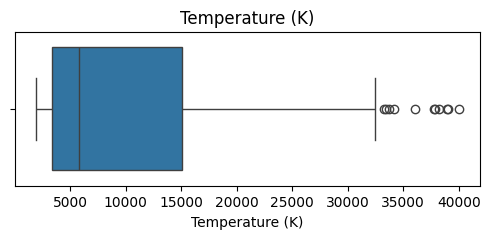

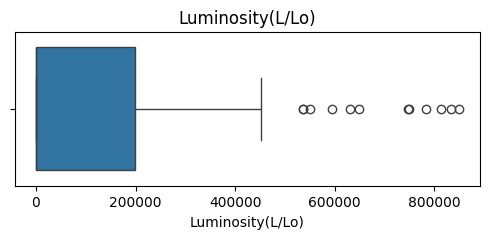

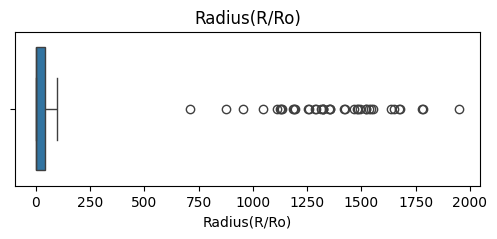

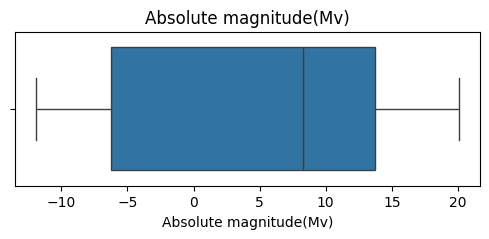

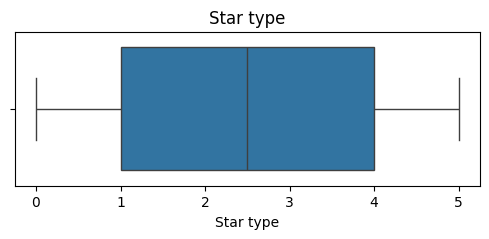

In [ ]:
for col in num_cols:

    plt.figure(figsize=(6,2))

    sns.boxplot(x=df[col])

    plt.title(col)

    plt.show()

In [ ]:
for col in num_cols:

    Q1=df[col].quantile(0.25)

    Q3=df[col].quantile(0.75)

    IQR=Q3-Q1

    lower=Q1-1.5*IQR

    upper=Q3+1.5*IQR

    df=df[(df[col]>=lower)&(df[col]<=upper)]

In [ ]:
encoder=LabelEncoder()

df["Star color"]=encoder.fit_transform(df["Star color"])

df["Spectral Class"]=encoder.fit_transform(df["Spectral Class"])

In [ ]:
df["Star type"]=encoder.fit_transform(df["Star type"])

In [ ]:
scaler=MinMaxScaler()

scaled=scaler.fit_transform(df)

df_minmax=pd.DataFrame(scaled,columns=df.columns)

df_minmax.head()

In [ ]:
standard=StandardScaler()

scaled=standard.fit_transform(df)

df_standard=pd.DataFrame(scaled,columns=df.columns)

df_standard.head()

,Temperature (K),Luminosity(L/Lo),Radius(R/Ro),Absolute magnitude(Mv),Star type,Star color,Spectral Class
0,-0.629950,-0.064576,0.081873,0.703483,-1.224745,0.362198,0.657438
1,-0.634414,-0.340780,-0.012523,0.882019,-1.224745,0.362198,0.657438
2,-0.710288,-0.369854,-0.324388,1.663113,-1.224745,0.362198,0.657438
3,-0.675955,-0.384391,0.022129,0.900616,-1.224745,0.362198,0.657438
4,-0.823755,-0.393404,-0.318414,2.168964,-1.224745,0.362198,0.657438


In [ ]:
corr=df.corr()

corr["Star type"].sort_values(ascending=False)

,Star type
Star type,1.000000
Temperature (K),0.766222
Luminosity(L/Lo),0.103285
Radius(R/Ro),-0.242165
Star color,-0.443600
Absolute magnitude(Mv),-0.756353
Spectral Class,-0.805194


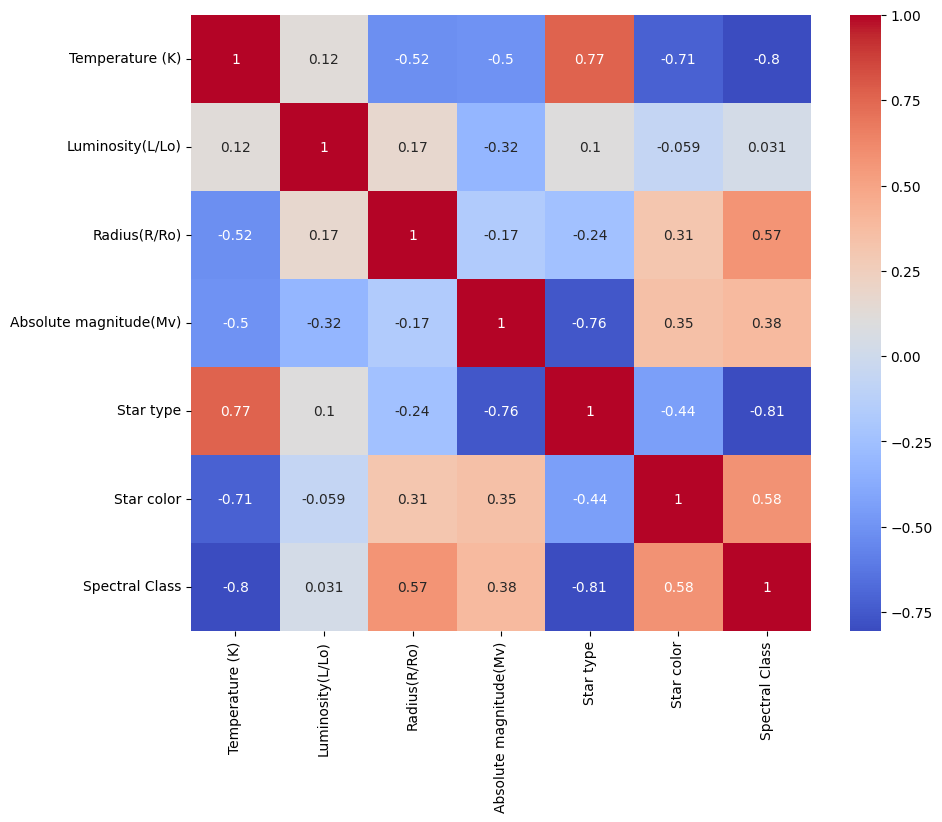

In [ ]:
plt.figure(figsize=(10,8))

sns.heatmap(df.corr(),annot=True,cmap="coolwarm")

plt.show()

In [ ]:
df["Surface_Area"]=4*3.1416*(df["Radius(R/Ro)"]**2)

df.head()

,Temperature (K),Luminosity(L/Lo),Radius(R/Ro),Absolute magnitude(Mv),Star type,Star color,Spectral Class,Surface_Area
0,3068,0.002400,0.1700,16.12,0,6,3,0.363169
1,3042,0.000500,0.1542,16.60,0,6,3,0.298799
2,2600,0.000300,0.1020,18.70,0,6,3,0.130741
3,2800,0.000200,0.1600,16.65,0,6,3,0.321700
4,1939,0.000138,0.1030,20.06,0,6,3,0.133317


In [ ]:
df["Temperature (K)"]=df["Temperature (K)"].astype(float)

df["Luminosity(L/Lo)"]=df["Luminosity(L/Lo)"].astype(float)

df.dtypes

,0
Temperature (K),float64
Luminosity(L/Lo),float64
Radius(R/Ro),float64
Absolute magnitude(Mv),float64
Star type,int64
Star color,int64
Spectral Class,int64
Surface_Area,float64


In [ ]:
for col in num_cols:

    lower=df[col].quantile(0.01)

    upper=df[col].quantile(0.99)

    df[col]=df[col].clip(lower,upper)

In [ ]:
X=df.drop("Star type",axis=1)

y=df["Star type"]

X_train,X_test,y_train,y_test=train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print(X_train.shape)

print(X_test.shape)

(96, 7)
(24, 7)


In [ ]:
!pip install imbalanced-learn

In [ ]:
from imblearn.over_sampling import SMOTE

smote=SMOTE(random_state=42)

X_train,y_train=smote.fit_resample(X_train,y_train)

print(X_train.shape)

(108, 7)


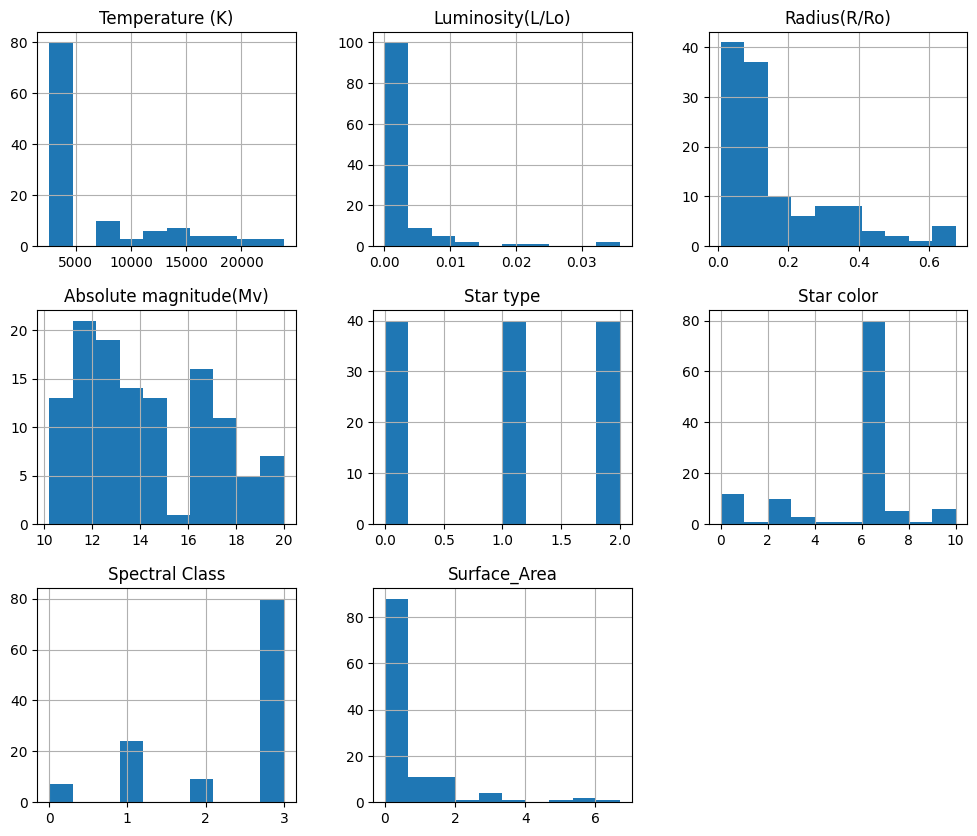

In [ ]:
df.hist(figsize=(12,10))

plt.show()

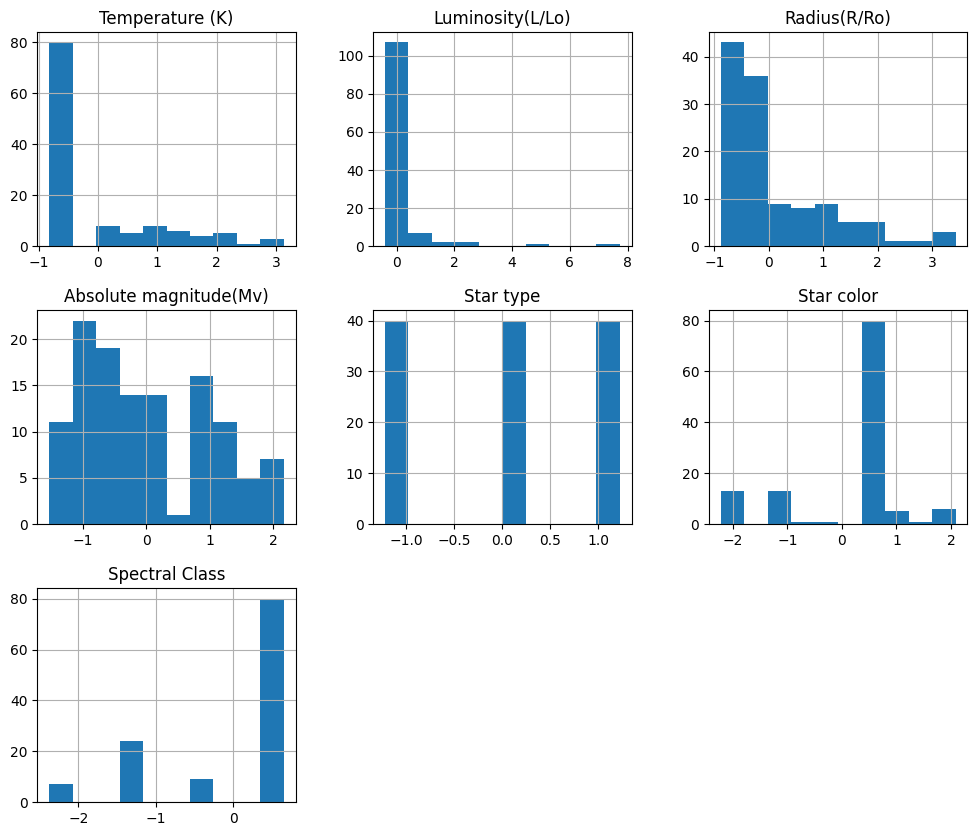

In [ ]:
df_standard.hist(figsize=(12,10))

plt.show()

In [ ]:
original=pd.read_csv("dataset/6 class csv.csv")

print("Original Shape :",original.shape)

print("Processed Shape :",df.shape)

print("Original Missing Values")

print(original.isnull().sum())

print("Processed Missing Values")

print(df.isnull().sum())

Original Shape : (240, 7)
Processed Shape : (120, 8)
Original Missing Values
Temperature (K)           0
Luminosity(L/Lo)          0
Radius(R/Ro)              0
Absolute magnitude(Mv)    0
Star type                 0
Star color                0
Spectral Class            0
dtype: int64
Processed Missing Values
Temperature (K)           0
Luminosity(L/Lo)          0
Radius(R/Ro)              0
Absolute magnitude(Mv)    0
Star type                 0
Star color                0
Spectral Class            0
Surface_Area              0
dtype: int64


In [ ]:
df.to_csv("Cleaned_Star_Dataset.csv",index=False)

print("Dataset Saved Successfully")

Dataset Saved Successfully


In [ ]:
from google.colab import files

files.download("Cleaned_Star_Dataset.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>